<!-- # Copyright (c) 2026 takotime808 -->
# Active Learning on Benchmark Functions

This tutorial shows the `multioutreg.active` prototype on analytic benchmark functions,
where the true response is known everywhere, so every surrogate can be scored on a large
held-out set. The design behind it is on the [Active Learning Plan](../active_learning.md) page.

**What this tutorial covers:**

1. [Benchmarks](#benchmarks): the analytic test problems, including multi-fidelity pairs
2. [Watching the loop](#watch): one-dimensional max-variance sampling, step by step
3. [Active vs passive designs](#vs): held-out error against random and Sobol designs
4. [Multi-output standardization](#multioutput): why output stds must be standardized
5. [Batch selection](#batch): top-k vs distance-penalized batches
6. [Optimization](#optimization): expected improvement and UCB
7. [Query-by-committee](#qbc): active learning for a model with no native uncertainty
8. [Multi-fidelity active learning](#mf): choosing the point *and* the fidelity level under a cost budget
9. [Summary](#summary)

Every experiment repeats over a few seeds and reports the median (line) and the range
(band). The seed counts and budgets are small so the notebook runs in a few minutes;
the conclusions are indicative, not a benchmark study.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

from multioutreg.active import (
    ActiveLearner,
    CommitteeSurrogate,
    MultiFidelityActiveLearner,
    fidelity_info,
    get_benchmark,
    heldout_metrics,
    level_trust,
    select_batch,
    BENCHMARKS,
)
from multioutreg.surrogates import (
    AdditiveCorrectionVFM,
    GaussianProcessSurrogate,
    KNeighborsSurrogate,
)

warnings.filterwarnings("ignore")  # GP optimizer convergence chatter

# Colors by role: active learning, passive baselines, and the multi-fidelity learner.
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False, "font.size": 9,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
    "figure.titlesize": 11,
})
SEEDS = range(3)


def gp():
    # Matern-5/2 GP with a length-scale floor and a few optimizer restarts. sklearn's
    # optimizer otherwise falls into a "short length scale + noise" optimum on small
    # designs (seen on Forrester with ~10 points), which ruins any variance-based acquisition.
    kernel = (ConstantKernel(1.0) * Matern(1.0, length_scale_bounds=(0.1, 100.0), nu=2.5)
              + WhiteKernel(1e-6, (1e-10, 1e-2)))
    return GaussianProcessSurrogate(kernel=kernel, n_restarts_optimizer=2, random_state=0)


def band(ax, x, runs, color, label):
    # Median line plus min-max band over seeds; runs has shape (n_seeds, len(x)).
    runs = np.asarray(runs)
    ax.fill_between(x, runs.min(0), runs.max(0), color=color, alpha=0.15, lw=0)
    ax.plot(x, np.median(runs, 0), color=color, label=label)


def passive(bench, n, method, seed, Xt, Yt, model=gp):
    X = bench.sample(n, method=method, seed=seed)
    return heldout_metrics(model().fit(X, bench(X)), Xt, Yt)["nrmse"]

<a id="benchmarks"></a>
## 1. Benchmarks

`multioutreg.active.benchmarks` defines eight analytic functions (definitions follow the
[Virtual Library of Simulation Experiments](https://www.sfu.ca/~ssurjano/)). The
multi-fidelity ones have a cheap `"lo"` and an expensive `"hi"` level, by default with a
10x cost ratio.

In [2]:
print(f"{'name':<15}{'dim':>4}{'outputs':>9}  levels   costs")
for name in BENCHMARKS:
    b = get_benchmark(name)
    n_out = b(b.sample(2, seed=0)).shape[1]
    print(f"{name:<15}{b.n_features:>4}{n_out:>9}  {'/'.join(b.levels):<8} {b.costs}")

name            dim  outputs  levels   costs
forrester         1        1  lo/hi    {'lo': 1.0, 'hi': 10.0}
branin            2        1  hi       {'hi': 1.0}
currin            2        1  lo/hi    {'lo': 1.0, 'hi': 10.0}
branin_currin     2        2  hi       {'hi': 1.0}
ishigami          3        1  hi       {'hi': 1.0}
hartmann3         3        1  hi       {'hi': 1.0}
park              4        1  lo/hi    {'lo': 1.0, 'hi': 10.0}
borehole          8        1  lo/hi    {'lo': 1.0, 'hi': 10.0}


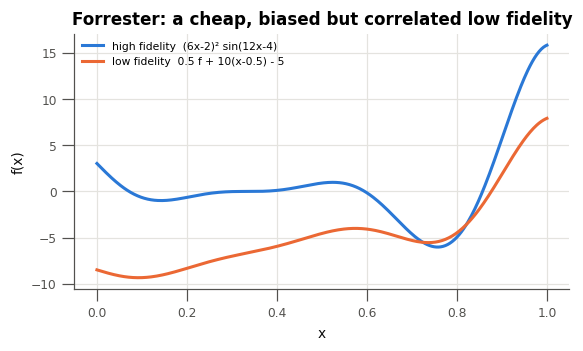

In [3]:
b = get_benchmark("forrester")
x = np.linspace(0, 1, 400)[:, None]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, b(x, "hi"), color=BLUE, label="high fidelity  (6x-2)² sin(12x-4)")
ax.plot(x, b(x, "lo"), color=ORANGE, label="low fidelity  0.5 f + 10(x-0.5) - 5")
ax.set(xlabel="x", ylabel="f(x)", title="Forrester: a cheap, biased but correlated low fidelity")
ax.legend(loc="upper left")
plt.show()

<a id="watch"></a>
## 2. Watching the loop

`ActiveLearner` takes a model factory and box bounds. Each `ask()` draws a fresh Sobol
candidate pool, scores it with the acquisition and returns the best point(s); `tell()`
adds the evaluated points. `run()` chains the two for a Python simulator.

Below, the max-variance acquisition (the GP's predictive variance, standardized by the
output's spread) starts from 3 points on Forrester. Each new point goes where the model
is least certain, so the design fills in the domain, and the region around the minimum
is resolved because the function's curvature keeps the variance high there.

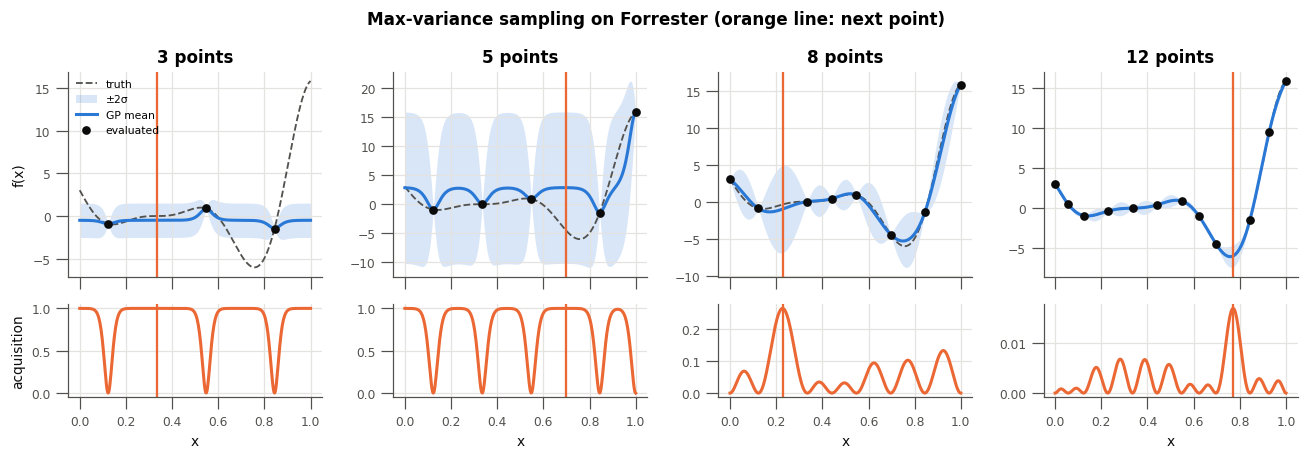

In [4]:
b = get_benchmark("forrester")
x = np.linspace(0, 1, 400)[:, None]
al = ActiveLearner(gp, b.bounds, acquisition="max_variance", random_state=0)
X0 = al.initial_design(3)
al.tell(X0, b(X0))

snapshots = {0, 2, 5, 9}
fig, axes = plt.subplots(2, 4, figsize=(12, 4.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
col = 0
for it in range(10):
    if it in snapshots:
        mean, std = al.fit().predict(x, return_std=True)
        mean, std = mean.ravel(), std.ravel()
        x_next = al.ask()
        top, bot = axes[0, col], axes[1, col]
        top.plot(x, b(x), color=MUTED, lw=1.2, ls="--", label="truth")
        top.fill_between(x.ravel(), mean - 2 * std, mean + 2 * std, color=BLUE, alpha=0.18, lw=0, label="±2σ")
        top.plot(x, mean, color=BLUE, label="GP mean")
        top.scatter(al.X_, al.Y_, color=INK, s=22, zorder=3, label="evaluated")
        top.axvline(x_next[0, 0], color=ORANGE, lw=1.5)
        top.set_title(f"{len(al.X_)} points")
        bot.plot(x, al.score(x), color=ORANGE)
        bot.axvline(x_next[0, 0], color=ORANGE, lw=1.5)
        bot.set_xlabel("x")
        col += 1
    else:
        x_next = al.ask()
    al.tell(x_next, b(x_next))
axes[0, 0].set_ylabel("f(x)")
axes[1, 0].set_ylabel("acquisition")
axes[0, 0].legend(loc="upper left", fontsize=7)
fig.suptitle("Max-variance sampling on Forrester (orange line: next point)", fontweight="bold")
fig.tight_layout()
plt.show()

<a id="vs"></a>
## 3. Active vs passive designs

The real question is whether active learning beats a good *passive* design of the same
size. Two baselines:

- **random**: the same loop with uniformly random scores (so points are i.i.d. uniform,
  apart from the batch-diversity penalty);
- **Sobol**: a one-shot scrambled Sobol design of each size, a strong space-filling baseline.

The metric is held-out NRMSE (RMSE divided by the test targets' std, averaged over
outputs) on 1,000 points.

In [5]:
problems = {"branin": 30, "hartmann3": 40, "ishigami": 60, "branin_currin": 30}
results = {}
for name, budget in problems.items():
    b = get_benchmark(name)
    Xt = b.sample(1000, method="random", seed=123)
    Yt = b(Xt)
    n_init = 2 * b.n_features + 2
    curves = {}
    for acq in ("max_variance", "random"):
        runs = []
        for s in SEEDS:
            al = ActiveLearner(gp, b.bounds, acquisition=acq, n_candidates=512, random_state=s)
            hist = al.run(b, n_init=n_init, n_iter=budget - n_init, X_test=Xt, Y_test=Yt)
            runs.append([h["nrmse"] for h in hist])
        curves[acq] = np.array(runs)
    n = np.arange(n_init, budget + 1)
    checkpoints = n[:: max(1, len(n) // 6)]
    curves["sobol"] = np.array([[passive(b, k, "sobol", s, Xt, Yt) for k in checkpoints] for s in SEEDS])
    results[name] = (n, checkpoints, curves)
    print(f"{name:<14} final NRMSE (median of {len(SEEDS)})  "
          + "  ".join(f"{k}: {np.median(v[:, -1]):.3f}" for k, v in curves.items()))

branin         final NRMSE (median of 3)  max_variance: 0.147  random: 0.164  sobol: 0.170
hartmann3      final NRMSE (median of 3)  max_variance: 0.380  random: 0.373  sobol: 0.357
ishigami       final NRMSE (median of 3)  max_variance: 0.639  random: 0.732  sobol: 0.734
branin_currin  final NRMSE (median of 3)  max_variance: 0.159  random: 0.197  sobol: 0.218


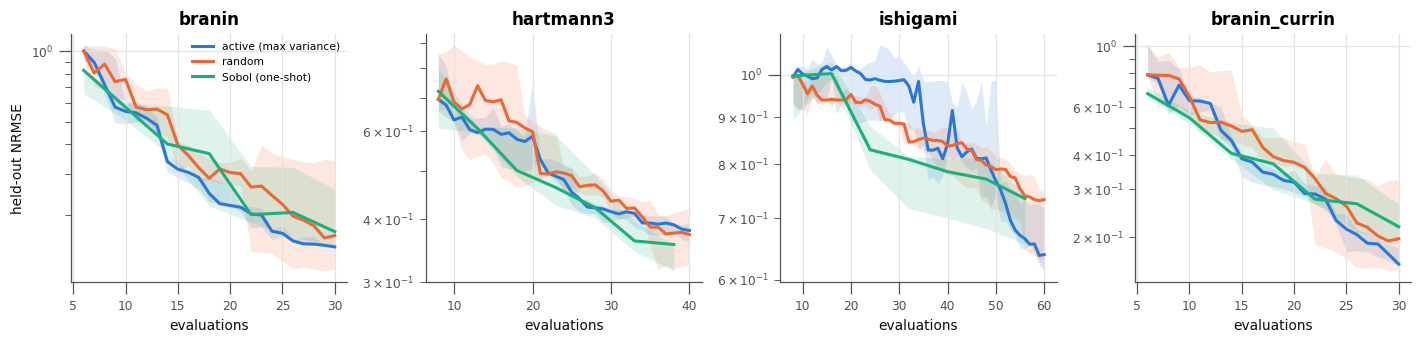

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (name, (n, checkpoints, curves)) in zip(axes, results.items()):
    band(ax, n, curves["max_variance"], BLUE, "active (max variance)")
    band(ax, n, curves["random"], ORANGE, "random")
    band(ax, checkpoints, curves["sobol"], AQUA, "Sobol (one-shot)")
    ax.set(yscale="log", title=name, xlabel="evaluations")
axes[0].set_ylabel("held-out NRMSE")
axes[0].legend(loc="upper right", fontsize=7)
fig.tight_layout()
plt.show()

**Reading the plot.** The differences are modest. Max-variance sampling ends ahead of
random and Sobol on Branin, Branin–Currin and Ishigami and is roughly level on Hartmann-3,
though Ishigami is still poorly fitted by every design at 60 points. A Sobol design is a hard
baseline for a GP: a stationary GP's variance depends only on *where* the data are, not on
the observed values (apart from refitted hyperparameters), so max-variance sampling is
itself a space-filling design. Expect larger gains when the response is non-stationary
(sharp features in part of the domain) and when the loop's other features matter:
stopping when good enough, batches, and cost awareness (section 8).

<a id="multioutput"></a>
## 4. Multi-output standardization

`branin_currin` has two outputs on very different scales (Branin roughly 0–300, Currin
roughly 1–14). `max_variance` divides each output's std by that output's observed spread
before summing; otherwise the raw sum is essentially the Branin variance alone. The cell
below turns standardization off by passing a unit `y_scale` and compares per-output error.

standardized  NRMSE  Branin 0.145   Currin 0.178
raw std       NRMSE  Branin 0.147   Currin 0.177


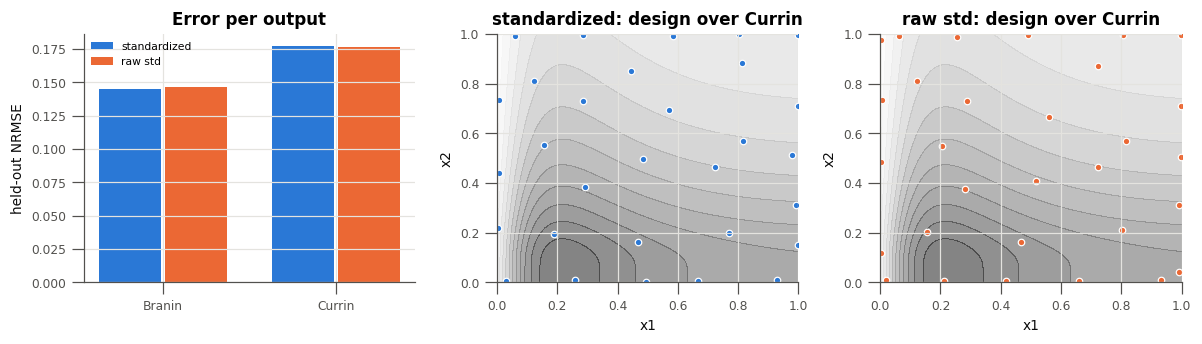

In [7]:
b = get_benchmark("branin_currin")
Xt = b.sample(1000, method="random", seed=123)
Yt = b(Xt)
per_output = {"standardized": [], "raw std": []}
designs = {}
for label, kw in [("standardized", {}), ("raw std", {"y_scale": np.ones(2)})]:
    for s in SEEDS:
        al = ActiveLearner(gp, b.bounds, acquisition_kwargs=kw, n_candidates=512, random_state=s)
        al.run(b, n_init=6, n_iter=24)
        pred = al.fit().predict(Xt)
        rmse = np.sqrt(((pred - Yt) ** 2).mean(0)) / Yt.std(0)
        per_output[label].append(rmse)
        designs.setdefault(label, al.X_)
for label, v in per_output.items():
    print(f"{label:<13} NRMSE  Branin {np.median(v, 0)[0]:.3f}   Currin {np.median(v, 0)[1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
w = 0.38
for i, (label, color) in enumerate([("standardized", BLUE), ("raw std", ORANGE)]):
    axes[0].bar(np.arange(2) + (i - 0.5) * w, np.median(per_output[label], 0), w * 0.95, color=color, label=label)
axes[0].set(xticks=[0, 1], xticklabels=["Branin", "Currin"], ylabel="held-out NRMSE", title="Error per output")
axes[0].legend(fontsize=7)
g = np.linspace(0, 1, 120)
G = np.array([[u, v] for v in g for u in g])
for ax, (label, color) in zip(axes[1:], [("standardized", BLUE), ("raw std", ORANGE)]):
    ax.contourf(g, g, b(G)[:, 1].reshape(120, 120), levels=14, cmap="Greys", alpha=0.5)
    ax.scatter(*designs[label].T, color=color, s=18, edgecolor="white", linewidth=0.8)
    ax.set(title=f"{label}: design over Currin", xlabel="x1", ylabel="x2")
fig.tight_layout()
plt.show()

<a id="batch"></a>
## 5. Batch selection

When a simulator runs several jobs at once, `ask(q)` returns `q` points. Taking the top
`q` scores puts the whole batch on one peak of the acquisition. `select_batch` instead
picks greedily and multiplies the remaining scores by `1 - exp(-d² / 2l²)` around each
pick (local penalization). The default length scale `l` is the typical spacing of a
space-filling design with as many points as the data plus the batch.

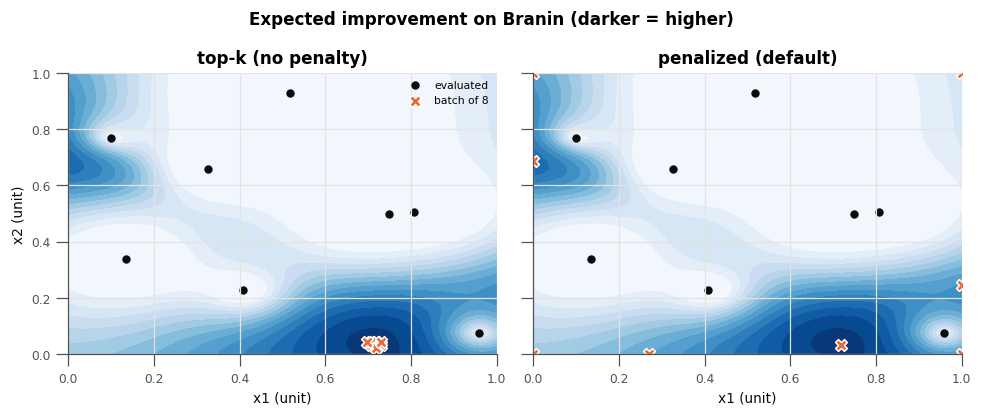

In [8]:
b = get_benchmark("branin")
al = ActiveLearner(gp, b.bounds, acquisition="ei", random_state=1)
X0 = al.initial_design(8)
al.tell(X0, b(X0))
g = np.linspace(0, 1, 90)
U = np.array([[u, v] for v in g for u in g])
scores = al.score(al.from_unit(U))
picks = {
    "top-k (no penalty)": select_batch(U, scores, 8, length_scale=1e-9),
    "penalized (default)": select_batch(U, scores, 8, U_train=al.to_unit(al.X_)),
}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, (label, idx) in zip(axes, picks.items()):
    ax.contourf(g, g, scores.reshape(90, 90), levels=14, cmap="Blues")
    ax.scatter(*al.to_unit(al.X_).T, color=INK, s=20, label="evaluated")
    ax.scatter(*U[idx].T, color=ORANGE, s=60, marker="X", edgecolor="white", linewidth=1, label="batch of 8")
    ax.set(title=label, xlabel="x1 (unit)")
axes[0].set_ylabel("x2 (unit)")
axes[0].legend(loc="upper right", fontsize=7)
fig.suptitle("Expected improvement on Branin (darker = higher)", fontweight="bold")
fig.tight_layout()
plt.show()

<a id="optimization"></a>
## 6. Optimization

With `acquisition="ei"`, `"pi"` or `"ucb"` the loop minimizes (or, with `minimize=False`,
maximizes) one output or a weighted sum of outputs (`weights`). The plot shows the gap
between the best value found and the known global minimum.

branin     ei      final gap (median) 1.66e-02
branin     ucb     final gap (median) 3.00e-02
branin     random  final gap (median) 8.88e-01
hartmann3  ei      final gap (median) 9.24e-03
hartmann3  ucb     final gap (median) 3.79e-02
hartmann3  random  final gap (median) 9.51e-02


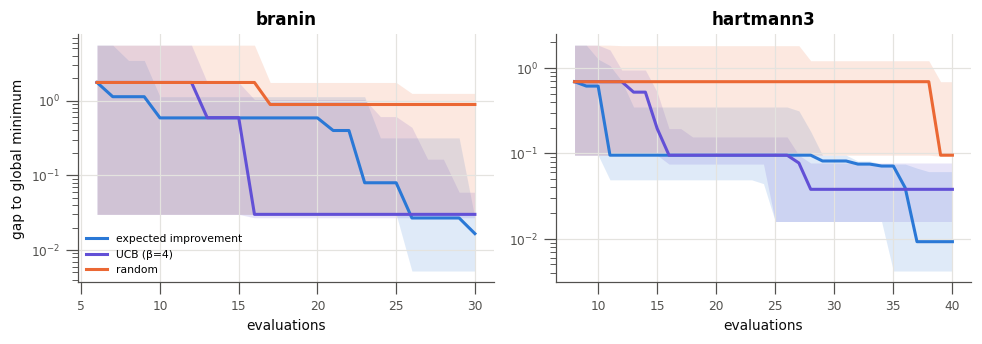

In [9]:
opt = {"branin": 30, "hartmann3": 40}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (name, budget) in zip(axes, opt.items()):
    b = get_benchmark(name)
    n_init = 2 * b.n_features + 2
    n = np.arange(n_init, budget + 1)
    for acq, color, label in [("ei", BLUE, "expected improvement"), ("ucb", VIOLET, "UCB (β=4)"), ("random", ORANGE, "random")]:
        runs = []
        for s in SEEDS:
            al = ActiveLearner(gp, b.bounds, acquisition=acq, n_candidates=1024, random_state=s)
            hist = al.run(b, n_init=n_init, n_iter=budget - n_init)
            runs.append([max(h["best"] - b.minimum, 1e-6) for h in hist])
        band(ax, n, runs, color, label)
        print(f"{name:<10} {acq:<7} final gap (median) {np.median(np.array(runs)[:, -1]):.2e}")
    ax.set(yscale="log", title=name, xlabel="evaluations")
axes[0].set_ylabel("gap to global minimum")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

<a id="qbc"></a>
## 7. Query-by-committee

Models such as KNN, linear models or plain trees have no predictive std;
`BaseSurrogate.predict(return_std=True)` returns zeros for them. The learner refuses that
(`predict_mean_std` raises), because zero std would read as "perfectly known".
`CommitteeSurrogate` fits bootstrap copies of any model and uses their disagreement as
the std. `penalize_train=True` also penalizes candidates near existing points, because a
committee's spread does not reliably shrink at the training data.

Refused: Model returned std == 0 everywhere for output(s) [0]; it has no native uncertainty. Wrap it in CommitteeSurrogate, or pass allow_zero_std=True.
final NRMSE (median): {'max_variance': 0.811, 'random': 0.8}


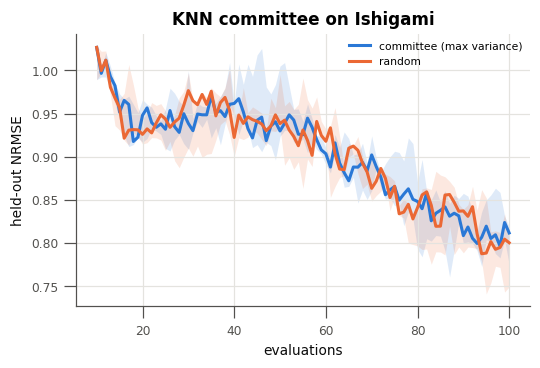

In [10]:
b = get_benchmark("ishigami")
try:
    ActiveLearner(KNeighborsSurrogate, b.bounds).run(b, n_init=8, n_iter=1)
except ValueError as e:
    print("Refused:", e)

Xt = b.sample(1000, method="random", seed=123)
Yt = b(Xt)
committee = lambda: CommitteeSurrogate(KNeighborsSurrogate, n_members=8)
knn_final = {}
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for acq, color, label in [("max_variance", BLUE, "committee (max variance)"), ("random", ORANGE, "random")]:
    runs = []
    for s in SEEDS:
        al = ActiveLearner(committee, b.bounds, acquisition=acq, penalize_train=True, n_candidates=512, random_state=s)
        hist = al.run(b, n_init=10, n_iter=90, X_test=Xt, Y_test=Yt)
        runs.append([h["nrmse"] for h in hist])
    band(ax, np.arange(10, 101), runs, color, label)
    knn_final[acq] = np.median(np.array(runs)[:, -1])
print("final NRMSE (median):", {k: round(v, 3) for k, v in knn_final.items()})
ax.set(title="KNN committee on Ishigami", xlabel="evaluations", ylabel="held-out NRMSE")
ax.legend(fontsize=7)
plt.show()

**Result: no gain here.** The committee runs, but its points are no better than random
ones. A bootstrap KNN committee disagrees mostly where resampling happens to drop a
neighbour, not where the function is hard, so its spread is a weak guide. Query-by-committee
is the right *mechanism* for models without native uncertainty; a more diverse committee
(for example different model families, or the Auto-Detect candidates) is the next thing to try.

<a id="mf"></a>
## 8. Multi-fidelity active learning

With fidelity levels, each query is a pair `(x, level)` and the budget is in cost units.
`MultiFidelityActiveLearner` asks how much of the **high-fidelity** predictive variance a
run at each level would remove, per unit cost.

For the AR1 model `AdditiveCorrectionVFM`, `f_hi = ρ f_lo + δ`, so
`var_hi = ρ² var_lo + var_δ`:

- a low-fidelity run at `x` can remove `ρ² var_lo(x)`;
- a high-fidelity run (by default *nested*: the low fidelity is also run at the same
  point, and both costs are paid) removes all of `var_hi(x)`.

The score is that reduction (standardized, summed over outputs) divided by the query's
cost. Two safeguards keep the cheap level from absorbing the budget when it does not
deserve to:

- **level trust**: a lower level's credit is multiplied by the squared lower confidence
  bound of its correlation with the high-fidelity data, which is zero until there are 6
  high-fidelity points;
- **`min_hi_fraction`** (default 0.25): a high-fidelity query is forced whenever
  high-fidelity spending falls below that share of the total.

The baselines spend the same budget only on the high fidelity: active (max variance)
and random.

In [11]:
def ar1():
    return AdditiveCorrectionVFM(lo_surrogate_cls=gp, hi_surrogate_cls=gp, oof_cv=None)


def at_costs(hist, grid):
    # Error of the latest model fitted within each cost on the grid (step function).
    cost = np.array([h["cost"] for h in hist])
    err = np.array([h["nrmse"] for h in hist])
    return np.array([err[cost <= c][-1] if np.any(cost <= c) else np.nan for c in grid])


mf_problems = {"forrester": 150, "currin": 300, "park": 500}
mf_results, mf_runs = {}, {}
for name, budget in mf_problems.items():
    b = get_benchmark(name)
    Xt = b.sample(1000, method="random", seed=123)
    Yt = b(Xt)
    sims = {lvl: (lambda X, lvl=lvl: b(X, lvl)) for lvl in b.levels}
    c_hi = b.costs["hi"]
    n_hi0 = b.n_features + 2
    n_lo0 = 3 * n_hi0
    grid = np.linspace(n_lo0 * b.costs["lo"] + n_hi0 * c_hi, budget, 25)
    curves = {"mf": [], "hi_active": [], "hi_random": []}
    for s in SEEDS:
        mf = MultiFidelityActiveLearner(ar1, b.bounds, b.levels, b.costs, n_candidates=512, random_state=s)
        hist = mf.run(sims, budget=budget, n_init={"lo": n_lo0, "hi": n_hi0}, X_test=Xt, Y_test=Yt)
        curves["mf"].append(at_costs(hist, grid))
        mf_runs.setdefault(name, mf)
        n_hi_budget = int(budget // c_hi)
        for acq, key in (("max_variance", "hi_active"), ("random", "hi_random")):
            al = ActiveLearner(gp, b.bounds, acquisition=acq, n_candidates=512, random_state=s)
            h = al.run(b, n_init=n_hi0, n_iter=n_hi_budget - n_hi0, X_test=Xt, Y_test=Yt)
            for r in h:
                r["cost"] = r["n_evals"] * c_hi
            curves[key].append(at_costs(h, grid))
    mf_results[name] = (grid, {k: np.array(v) for k, v in curves.items()})
    print(f"{name:<10} final NRMSE (median)  "
          + "  ".join(f"{k}: {np.nanmedian(v[:, -1]):.4f}" for k, v in mf_results[name][1].items())
          + f"   | high-fidelity share of MF spend: {mf.spent_['hi'] / mf.total_spent:.0%}")

forrester  final NRMSE (median)  mf: 0.0140  hi_active: 0.0078  hi_random: 0.1208   | high-fidelity share of MF spend: 87%
currin     final NRMSE (median)  mf: 0.0517  hi_active: 0.1807  hi_random: 0.2714   | high-fidelity share of MF spend: 53%
park       final NRMSE (median)  mf: 0.0027  hi_active: 0.0087  hi_random: 0.0075   | high-fidelity share of MF spend: 64%


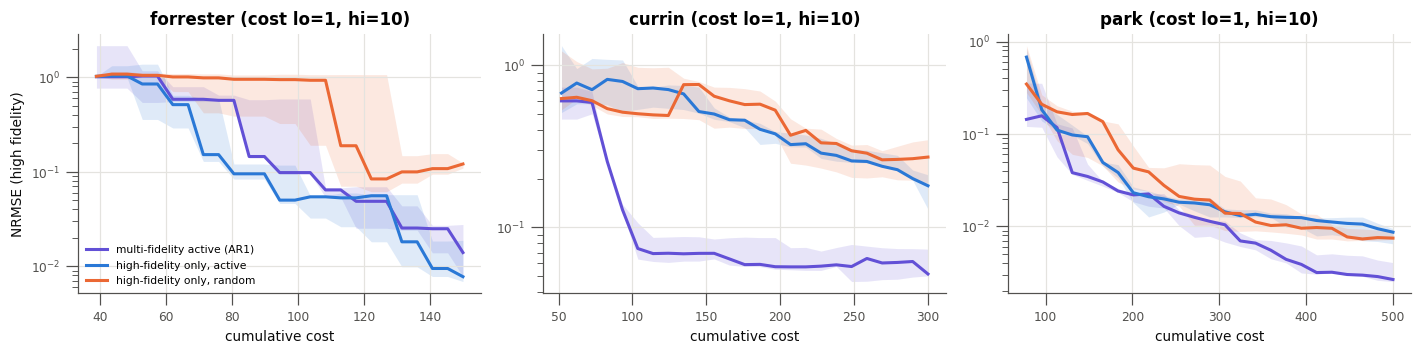

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, (name, (grid, curves)) in zip(axes, mf_results.items()):
    band(ax, grid, curves["mf"], VIOLET, "multi-fidelity active (AR1)")
    band(ax, grid, curves["hi_active"], BLUE, "high-fidelity only, active")
    band(ax, grid, curves["hi_random"], ORANGE, "high-fidelity only, random")
    ax.set(yscale="log", title=f"{name} (cost lo=1, hi=10)", xlabel="cumulative cost")
axes[0].set_ylabel("NRMSE (high fidelity)")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

**Reading the plot.** On Currin and Park the multi-fidelity learner reaches a given
high-fidelity error at a fraction of the cost of spending on the high fidelity alone; the
cheap level is informative and the learner leans on it. On one-dimensional Forrester,
high-fidelity-only active learning is as good or better: 15 high-fidelity points already
pin down a 1-D function, and the low level's linear bias has to be learned by `δ` from the
same few points. Multi-fidelity pays off when the high fidelity is too expensive to cover
the domain on its own.

Which level did the learner pick, and where? The strip below shows the sequence of
queries for the first seed of each problem, and the right panel shows where the Forrester
queries landed.

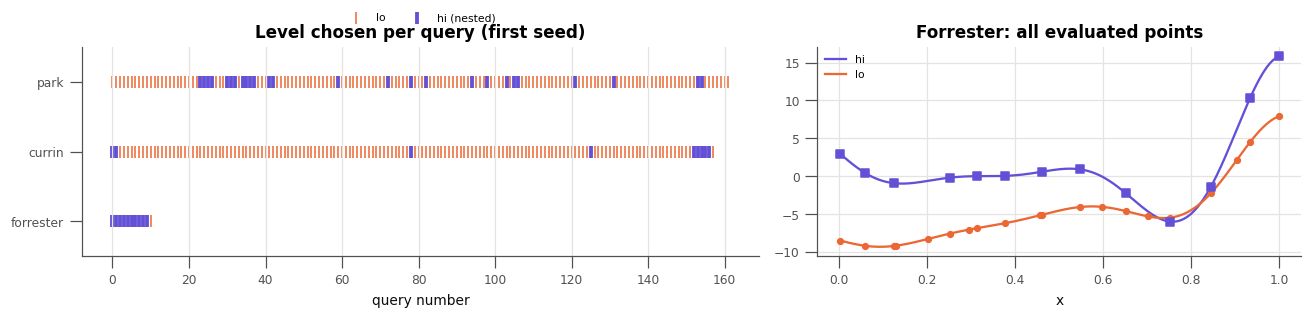

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw={"width_ratios": [1.4, 1]})
for row, (name, mf) in enumerate(mf_runs.items()):
    levels = [h["level"] for h in mf.history_[1:]]
    x = np.arange(len(levels))
    is_hi = np.array([lvl == "hi" for lvl in levels])
    axes[0].scatter(x[~is_hi], np.full((~is_hi).sum(), row), color=ORANGE, s=60, marker="|", linewidths=1, label="lo" if row == 0 else None)
    axes[0].scatter(x[is_hi], np.full(is_hi.sum(), row), color=VIOLET, s=60, marker="|", linewidths=2.5, label="hi (nested)" if row == 0 else None)
axes[0].set(yticks=range(len(mf_runs)), yticklabels=list(mf_runs), ylim=(-0.5, len(mf_runs) - 0.5),
            xlabel="query number", title="Level chosen per query (first seed)")
axes[0].grid(axis="y", visible=False)
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=2)

b = get_benchmark("forrester")
mf = mf_runs["forrester"]
xg = np.linspace(0, 1, 400)[:, None]
axes[1].plot(xg, b(xg, "hi"), color=VIOLET, lw=1.5, label="hi")
axes[1].plot(xg, b(xg, "lo"), color=ORANGE, lw=1.5, label="lo")
axes[1].scatter(mf.data_["lo"][0], mf.data_["lo"][1], color=ORANGE, s=14, zorder=3)
axes[1].scatter(mf.data_["hi"][0], mf.data_["hi"][1], color=VIOLET, s=34, marker="s", zorder=3)
axes[1].set(title="Forrester: all evaluated points", xlabel="x")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

### When the cheap level is useless

The safeguards matter when the low fidelity carries no information. Below, the "low
fidelity" is pure noise. With `trust_z=None` and `min_hi_fraction=0` the learner trusts
the AR1 variance split as fitted. With only 3 high-fidelity points, least squares fits a
huge `ρ` to the noise, `ρ² var_lo` looks large everywhere, and the budget drains into
the noise. With the defaults the learner keeps buying high-fidelity runs.

The dashed line is a plain GP fitted to the high-fidelity points the default learner
collected, ignoring the low level.

no safeguards                                 final NRMSE 2.380   high-fidelity share 15%   GP on its high-fidelity points alone 1.023
defaults (trust + 25% high-fidelity floor)    final NRMSE 2.020   high-fidelity share 85%   GP on its high-fidelity points alone 0.017


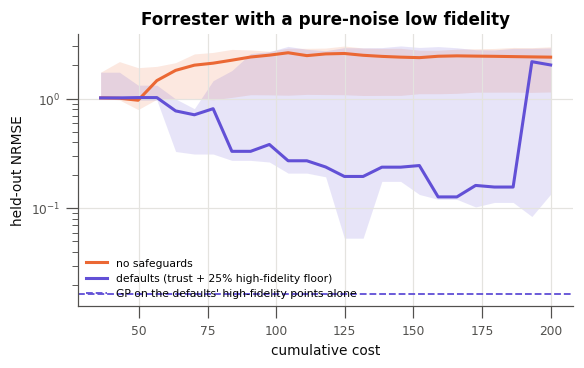

In [14]:
b = get_benchmark("forrester")
Xt = b.sample(1000, method="random", seed=123)
Yt = b(Xt)
fig, ax = plt.subplots(figsize=(6, 3.2))
for label, kw, color in [("no safeguards", dict(trust_z=None, min_hi_fraction=0.0), ORANGE),
                         ("defaults (trust + 25% high-fidelity floor)", {}, VIOLET)]:
    grid = np.linspace(36, 200, 25)
    runs, shares, hi_only = [], [], []
    for s in SEEDS:
        rng = np.random.default_rng(s)
        sims = {"lo": lambda X, rng=rng: rng.standard_normal((len(X), 1)), "hi": lambda X: b(X, "hi")}
        mf = MultiFidelityActiveLearner(ar1, b.bounds, b.levels, b.costs, n_candidates=512, random_state=s, **kw)
        hist = mf.run(sims, budget=200, n_init={"lo": 6, "hi": 3}, X_test=Xt, Y_test=Yt)
        runs.append(at_costs(hist, grid))
        shares.append(mf.spent_["hi"] / mf.total_spent)
        hi_only.append(heldout_metrics(gp().fit(*mf.data_["hi"]), Xt, Yt)["nrmse"])
    band(ax, grid, runs, color, label)
    print(f"{label:<45} final NRMSE {np.median(np.array(runs)[:, -1]):.3f}   high-fidelity share {np.median(shares):.0%}"
          f"   GP on its high-fidelity points alone {np.median(hi_only):.3f}")
ax.axhline(np.median(hi_only), color=VIOLET, ls="--", lw=1.2, label="GP on the defaults' high-fidelity points alone")
ax.set(yscale="log", title="Forrester with a pure-noise low fidelity", xlabel="cumulative cost", ylabel="held-out NRMSE")
ax.legend(fontsize=7)
plt.show()

**What the safeguards do and do not fix.** They fix the *spending*: with the defaults most
of the budget goes to the high fidelity instead of the noise. They do not fix the
*model*: `AdditiveCorrectionVFM` still fuses the noise level through `ρ f_lo`, so its error
stays erratic and can jump when a late low-fidelity run refits `ρ`. A GP on the same
high-fidelity points alone does far better. The next step in the plan is model selection
across levels: once a level's trust stays near zero, drop it from the surrogate.

<a id="summary"></a>
## 9. Summary

- **Max-variance active learning** is a sound default for global accuracy with a GP, but on
  smooth, stationary problems a Sobol design of the same size is nearly as good. The gains
  are modest here; the loop's other features (stopping, batches, costs) carry much of the value.
- **Standardize before aggregating outputs.** With per-output stationary GPs it hardly
  changed the result on Branin–Currin, but without it the acquisition depends on the
  outputs' units; it matters once outputs have different models or length scales.
- **Batches need diversity.** Plain top-k puts the whole batch on one peak.
- **EI / UCB** close in on the optimum of Branin and Hartmann-3 within a few dozen runs,
  far ahead of random search.
- **Query-by-committee** brings models without native uncertainty into the loop, but a
  bootstrap KNN committee gave no gain over random points.
- **Multi-fidelity:** on Currin and Park, cost-aware selection reaches a given
  high-fidelity error at a fraction of the cost of the high fidelity alone; on 1-D
  Forrester it does not help. The trust factor and high-fidelity floor stop a useless cheap
  level from absorbing the budget, but dropping such a level from the model is still to do.

Next steps (from the plan): integrated-variance (ALC) criteria, conformal-width scores,
level selection for multi-fidelity models, mixed-level batches, and a `mor_cli` ask/tell
command that reads and writes CSVs.